In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import hankel1

def curva(t):
    # t en [0, 2*pi]
    xt = np.cos(t) + 0.65 * np.cos(2 * t) - 0.65
    yt = 1.5 * np.sin(t)
    return np.array([xt, yt])

def curva_derivada(t):
    # Derivada analítica de la curva x'(t)
    dxt = -np.sin(t) - 2 * 0.65 * np.sin(2 * t)
    dyt = 1.5 * np.cos(t)
    return np.array([dxt, dyt])

def normal_vector(t):
    # Vector normal unitario exterior a la curva
    dt = curva_derivada(t)
    norm = np.linalg.norm(dt, axis=0) if isinstance(t, np.ndarray) else np.linalg.norm(dt)
    # n = (y' / ||x'||, -x' / ||x'||) o rotado adecuadamente
    nx = dt[1] / norm
    ny = -dt[0] / norm
    return np.array([nx, ny])

def phi_incidente(k, d, x):
    # Onda plana: e^(i * k * (d . x))
    return np.exp(1j * k * np.dot(d, x))

def dG_dn(k, x, y, ny):
    """
    Calcula la derivada normal de G(x, y) con respecto a y en la dirección del vector normal ny.
    G(x, y) = H_0^{(1)}(k |x-y|)
    """
    diff = y - x
    r = np.linalg.norm(diff, axis=0) if (isinstance(x, np.ndarray) and x.ndim > 1) or (isinstance(y, np.ndarray) and y.ndim > 1) else np.linalg.norm(diff)

    # Derivada de H_0^{(1)}(kr) respecto a r es -k * H_1^{(1)}(kr)
    # Grad_y r = (y - x) / r
    # Grad_y G(x,y) = -k * H_1^{(1)}(kr) * ((y - x) / r)
    grad_y_G = -k * hankel1(1, k * r) * (diff / r)

    # Producto escalar con el vector normal ny
    if isinstance(ny, np.ndarray) and ny.ndim > 1:
        return np.sum(grad_y_G * ny, axis=0)
    else:
        return np.dot(grad_y_G, ny)

In [ ]:
# --- Parámetros de prueba ---
k = 2.0
d = np.array([1.0, 0.0])
x_test = np.array([0.5, 0.5])  # Punto de observación exterior
t_test = 1.25                   # Parámetro en la curva

y_test = curva(t_test)
ny_test = normal_vector(t_test)

# 1. Derivada analítica
derivada_analitica = dG_dn(k, x_test, y_test, ny_test)

# 2. Derivada por diferencias finitas centrales
eps = 1e-6
y_plus = y_test + eps * ny_test
y_minus = y_test - eps * ny_test

G_plus = hankel1(0, k * np.linalg.norm(x_test - y_plus))
G_minus = hankel1(0, k * np.linalg.norm(x_test - y_minus))

derivada_fd = (G_plus - G_minus) / (2 * eps)

# 3. Resultados y comparación
print(f"Derivada analítica : {derivada_analitica}")
print(f"Derivada por F.F.  : {derivada_fd}")
print(f"Error absoluto     : {np.abs(derivada_analitica - derivada_fd):.2e}")

Derivada analítica : (-0.14859564590056468-0.249921804324867j)
Derivada por F.F.  : (-0.1485956459823523-0.24992180425176258j)
Error absoluto     : 1.10e-10


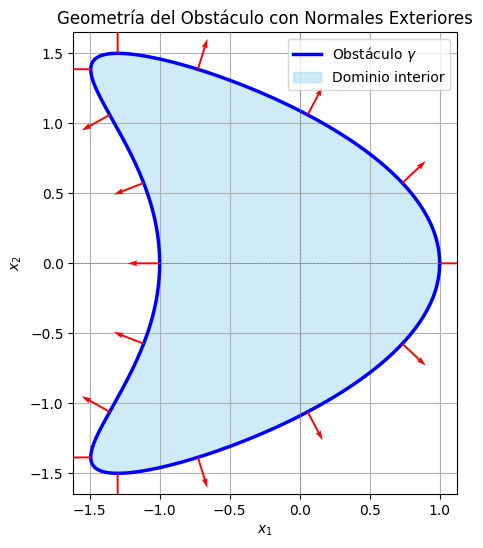

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_obstaculo():
    # 1. Discretizar el parámetro t en [0, 2*pi]
    t_vals = np.linspace(0, 2 * np.pi, 400)

    # 2. Evaluar la curva punto a punto
    # (asumiendo que curva(t) devuelve un array numpy [xt, yt])
    puntos = np.array([curva(ti) for ti in t_vals])
    xt, yt = puntos[:, 0], puntos[:, 1]

    plt.figure(figsize=(6, 6))

    # 3. Graficar el contorno y rellenar el interior
    plt.plot(xt, yt, 'b-', linewidth=2.5, label='Obstáculo $\\gamma$')
    plt.fill(xt, yt, color='skyblue', alpha=0.4, label='Dominio interior')

    # 4. Opcional: Dibujar algunos vectores normales exteriores para control visual
    t_quiver = np.linspace(0, 2 * np.pi, 16, endpoint=False)
    for ti in t_quiver:
        pos = curva(ti)
        n = normal_vector(ti)
        plt.quiver(pos[0], pos[1], n[0], n[1], color='red', scale=12, width=0.005, zorder=3)

    # Estética del gráfico
    plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
    plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.title('Geometría del Obstáculo con Normales Exteriores')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.show()

# Ejecutar la función (asumiendo que curva(t) y normal_vector(t) ya están definidas)
plot_obstaculo()

Resolución completada con éxito.
Dimensión del sistema: 32 x 32
Coeficientes a_j (primeros 5): [-1.13889483 -3.15072185j 26.34769212+14.39457153j
 -3.53526904+18.71131153j -3.40893547 +0.02598933j
  1.02315821 -4.50032697j]


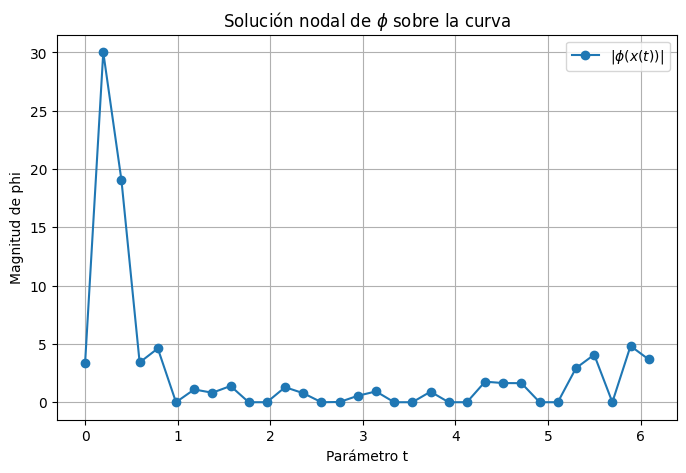

In [ ]:
def lagrange_basis(t, j, nodes):
    """
    Evalúa la j-ésima función base de Lagrange l_j(t) definida sobre los nodos dados,
    asumiendo periodicidad o interpolación estándar en [0, 2pi].
    """
    N = len(nodes)
    val = 1.0
    t_j = nodes[j]
    for m in range(N):
        if m == j:
            continue
        t_m = nodes[m]
        # Producto para polinomios de Lagrange
        # Para evitar problemas con intervalos periódicos, evaluamos la distancia estándar
        val *= (t - t_m) / (t_j - t_m)
    return val

def resolver_bem(k, d, N):
    # Definir nodos de colocación equiespaciados en [0, 2*pi)
    nodes = np.linspace(0, 2 * np.pi, N, endpoint=False)

    M = np.zeros((N, N), dtype=complex)
    b = np.zeros(N, dtype=complex)

    # Puntos y vectores tangentes/normales en los nodos
    X_nodes = np.array([curva(t) for t in nodes]).T  # Shape (2, N)
    D_nodes = np.array([curva_derivada(t) for t in nodes]).T
    Norms_dt = np.linalg.norm(D_nodes, axis=0)
    N_nodes = np.array([normal_vector(t) for t in nodes]).T  # Shape (2, N)

    # Lado derecho b_i = -phi_incidente(x(t_i))
    for i in range(N):
        xi = X_nodes[:, i]
        b[i] = -phi_incidente(k, d, xi)

    # Matriz del sistema M_ij
    # Usaremos cuadratura de los trapecios con M_quad puntos de integración
    M_quad = 3 * N  # Puntos de integración fina para la integral
    tau_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_quad = (2 * np.pi) / M_quad

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0)
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    for i in range(N):
        xi = X_nodes[:, i]
        for j in range(N):
            # Término integral computado por cuadratura
            integral_val = 0.0
            for q in range(M_quad):
                t_q = tau_quad[q]
                y_q = X_quad[:, q]
                ny_q = N_quad[:, q]
                dt_norm_q = Norms_dt_quad[q]

                # Evaluar base l_j en el punto de cuadratura t_q
                l_j_val = lagrange_basis(t_q, j, nodes)

                # Manejar núcleo singular cuando xi se acerca a y_q (i == q geométricamente)
                if i == q:
                    kernel_val = 0.0  # Aproximación simple para la diagonal en contornos suaves
                else:
                    kernel_val = dG_dn(k, xi, y_q, ny_q)

                integral_val += kernel_val * l_j_val * dt_norm_q * w_quad

            # M_ij = 0.5 * delta_ij + Integral
            delta_ij = 1.0 if i == j else 0.0
            M[i, j] = 0.5 * delta_ij + integral_val

    # Resolver el sistema lineal M * a = b
    a = np.linalg.solve(M, b)
    return nodes, a, X_nodes


# ==========================================
# 4. Ejecución y Visualización
# ==========================================
if __name__ == "__main__":
    k_par = 1.0
    d_par = np.array([1.0, 0.0])
    N_nodes = 32  # Número de nodos

    nodes, a_coefs, X_nodes = resolver_bem(k_par, d_par, N_nodes)

    print("Resolución completada con éxito.")
    print(f"Dimensión del sistema: {N_nodes} x {N_nodes}")
    print(f"Coeficientes a_j (primeros 5): {a_coefs[:5]}")

    # Graficar la magnitud de la solución phi en el contorno
    plt.figure(figsize=(8, 5))
    plt.plot(nodes, np.abs(a_coefs), 'o-', label='$|\\phi(x(t))|$')
    plt.xlabel('Parámetro t')
    plt.ylabel('Magnitud de phi')
    plt.title('Solución nodal de $\\phi$ sobre la curva')
    plt.grid(True)
    plt.legend()
    plt.show()

<>:185: SyntaxWarning: invalid escape sequence '\g'
<>:185: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1102/6466416.py:185: SyntaxWarning: invalid escape sequence '\g'
  plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Obstáculo $\gamma$')


Resolviendo BEM con cambio de variable...
Calculando campo en la malla 2D...


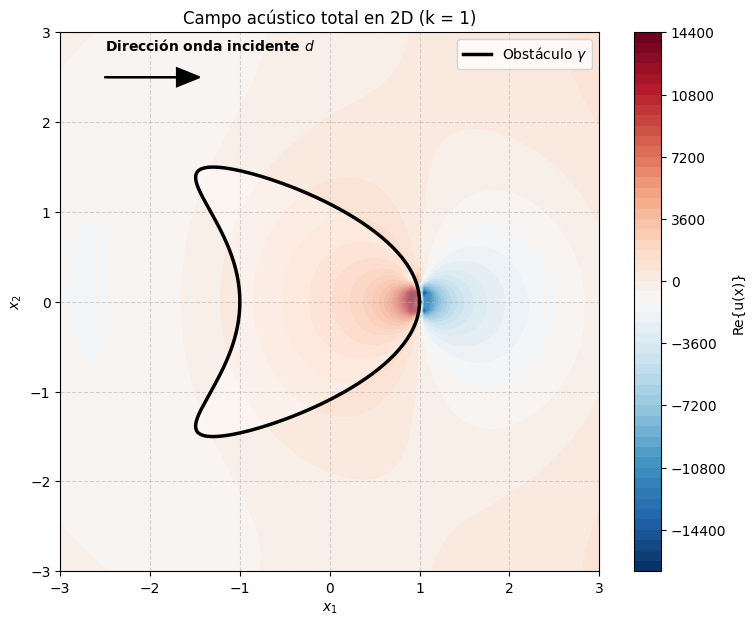

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import hankel1

# ==========================================
# 1. Definición de la Geometría (Curva original de Colton & Kress)
# ==========================================
def curva(t):
    xt = np.cos(t) + 0.65 * np.cos(2 * t) - 0.65
    yt = 1.5 * np.sin(t)
    return np.array([xt, yt])

def curva_derivada(t):
    dxt = -np.sin(t) - 1.3 * np.sin(2 * t)
    dyt = 1.5 * np.cos(t)
    return np.array([dxt, dyt])

def normal_vector(t):
    dt = curva_derivada(t)
    norm = np.linalg.norm(dt, axis=0)
    # Vector normal apuntando correctamente hacia el EXTERIOR
    nx = -dt[1] / norm
    ny = dt[0] / norm
    return np.array([nx, ny])

def phi_incidente(k, d, x):
    return np.exp(1j * k * np.dot(d, x))

def dG_dn(k, x, y, ny):
    diff = y - x
    r = np.linalg.norm(diff, axis=0)
    if r == 0:
        return 0.0
    grad_y_G = -k * hankel1(1, k * r) * (diff / r)
    return np.sum(grad_y_G * ny, axis=0) if ny.ndim > 1 else np.dot(grad_y_G, ny)

def lagrange_basis(t, j, nodes):
    N = len(nodes)
    val = 1.0
    t_j = nodes[j]
    for m in range(N):
        if m == j:
            continue
        t_m = nodes[m]
        val *= (t - t_m) / (t_j - t_m)
    return val


# ==========================================
# 2. Resolución BEM con Cambio de Variable (Kress)
# ==========================================
def resolver_bem_con_mapeo(k, d, N):
    nodes = np.linspace(0, 2 * np.pi, N, endpoint=False)
    M = np.zeros((N, N), dtype=complex)
    b = np.zeros(N, dtype=complex)

    X_nodes = np.array([curva(t) for t in nodes]).T  # Shape (2, N)

    for i in range(N):
        xi = X_nodes[:, i]
        b[i] = -phi_incidente(k, d, xi)

    # Cuadratura con cambio de variable periódico (Transformación de Kress)
    M_quad = 3 * N
    u_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_u = (2 * np.pi) / M_quad

    sigma = 1.0  # Parámetro de suavizado del mapeo
    tau_quad = u_quad - sigma * np.sin(u_quad)
    dtau_du = 1.0 - sigma * np.cos(u_quad)  # Derivada g'(u)

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0) * dtau_du
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    for i in range(N):
        xi = X_nodes[:, i]
        for j in range(N):
            integral_val = 0.0
            for q in range(M_quad):
                t_q = tau_quad[q]
                y_q = X_quad[:, q]
                ny_q = N_quad[:, q]
                dt_norm_q = Norms_dt_quad[q]

                l_j_val = lagrange_basis(t_q, j, nodes)

                # Tratamiento de la diagonal / auto-intersección
                dist_geo = np.linalg.norm(xi - y_q)
                if dist_geo < 1e-12:
                    kernel_val = 0.0
                else:
                    kernel_val = dG_dn(k, xi, y_q, ny_q)

                integral_val += kernel_val * l_j_val * dt_norm_q * w_u

            delta_ij = 1.0 if i == j else 0.0
            M[i, j] = 0.5 * delta_ij + integral_val

    a = np.linalg.solve(M, b)
    return nodes, a, X_nodes


# ==========================================
# 3. Evaluación 2D Vectorizada y Optimizada
# ==========================================
def evaluar_campo_2d(k, d, X_nodes, a_coefs, grid_x, grid_y):
    Ny, Nx = grid_x.shape
    X_grid = np.stack([grid_x.ravel(), grid_y.ravel()], axis=-1)  # (P, 2)
    P = X_grid.shape[0]

    u_inc = np.exp(1j * k * (X_grid @ d)).reshape(Ny, Nx)

    M_quad = 120
    tau_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_quad = (2 * np.pi) / M_quad

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0)
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    N_nodes_len = len(a_coefs)
    nodes = np.linspace(0, 2 * np.pi, N_nodes_len, endpoint=False)

    L_matrix = np.zeros((N_nodes_len, M_quad))
    for j in range(N_nodes_len):
        for q, t_q in enumerate(tau_quad):
            L_matrix[j, q] = lagrange_basis(t_q, j, nodes)

    phi_quad = a_coefs @ L_matrix  # (M_quad,)

    u_scat_flat = np.zeros(P, dtype=complex)
    eps_reg = 0.02  # Leve suavizado físico para evitar singularidades estéticas en la malla 2D

    for q in range(M_quad):
        y_q = X_quad[:, q]
        ny_q = N_quad[:, q]
        dt_norm = Norms_dt_quad[q]
        phi_q = phi_quad[q]

        diff = y_q - X_grid
        r_exact = np.linalg.norm(diff, axis=1)
        r_reg = np.sqrt(r_exact**2 + eps_reg**2)

        grad_y_G = -k * hankel1(1, k * r_reg[:, None]) * (diff / r_reg[:, None])
        dG_dn_vals = np.sum(grad_y_G * ny_q, axis=1)

        u_scat_flat += dG_dn_vals * phi_q * dt_norm * w_quad

    u_scat = u_scat_flat.reshape(Ny, Nx)
    return u_inc + u_scat


# ==========================================
# 4. Ejecución Principal y Visualización
# ==========================================
if __name__ == "__main__":
    k_par = 1
    d_par = np.array([1.0, 0.0])  # Incidencia de izquierda a derecha
    N_nodes = 50                  # Número de nodos

    print("Resolviendo BEM con cambio de variable...")
    nodes, a_coefs, X_nodes = resolver_bem_con_mapeo(k_par, d_par, N_nodes)

    print("Calculando campo en la malla 2D...")
    resolution = 90
    x_vals = np.linspace(-3.0, 3.0, resolution)
    y_vals = np.linspace(-3.0, 3.0, resolution)
    GX, GY = np.meshgrid(x_vals, y_vals)

    U_field = evaluar_campo_2d(k_par, d_par, X_nodes, a_coefs, GX, GY)

    # Gráfico 2D
    plt.figure(figsize=(9, 7))
    contour = plt.contourf(GX, GY, np.real(U_field), levels=60, cmap='RdBu_r')
    plt.colorbar(contour, label='Re{u(x)}')

    # Dibujar obstáculo
    t_plot = np.linspace(0, 2 * np.pi, 300)
    puntos_plot = np.array([curva(t) for t in t_plot])
    xt_obs, yt_obs = puntos_plot[:, 0], puntos_plot[:, 1]

    plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Obstáculo $\gamma$')
    plt.fill(xt_obs, yt_obs, color='white', alpha=0.35)

    # Flecha de dirección de la onda incidente
    plt.arrow(-2.5, 2.5, 0.8, 0.0, head_width=0.2, head_length=0.25,
              fc='black', ec='black', linewidth=1.5, zorder=5)
    plt.text(-2.5, 2.8, 'Dirección onda incidente $d$', fontsize=10, fontweight='bold', color='black')

    plt.title(f'Campo acústico total en 2D (k = {k_par})')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

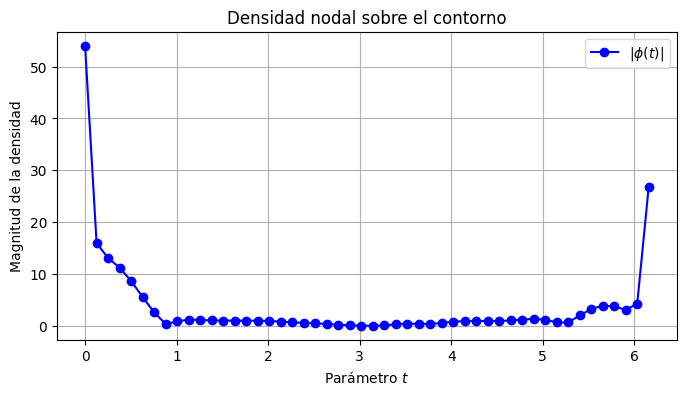

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(nodes, np.abs(a_coefs), 'o-', color='b', label='$|\\phi(t)|$')
plt.xlabel('Parámetro $t$')
plt.ylabel('Magnitud de la densidad')
plt.title('Densidad nodal sobre el contorno')
plt.grid(True)
plt.legend()
plt.show()

<>:185: SyntaxWarning: invalid escape sequence '\g'
<>:185: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1102/2323066284.py:185: SyntaxWarning: invalid escape sequence '\g'
  plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Obstáculo $\gamma$')


Resolviendo BEM con cambio de variable...
Calculando campo en la malla 2D...


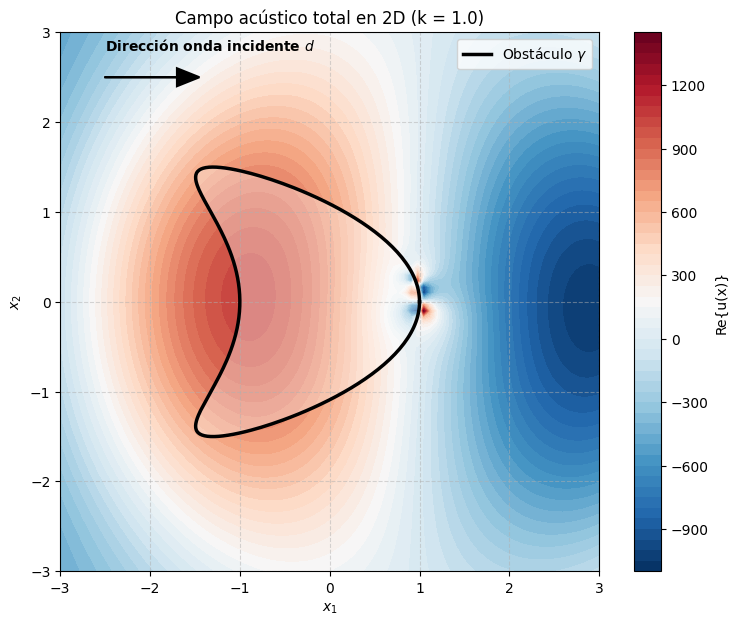

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import hankel1

# ==========================================
# 1. Definición de la Geometría (Curva original de Colton & Kress)
# ==========================================
def curva(t):
    xt = np.cos(t) + 0.65 * np.cos(2 * t) - 0.65
    yt = 1.5 * np.sin(t)
    return np.array([xt, yt])

def curva_derivada(t):
    dxt = -np.sin(t) - 1.3 * np.sin(2 * t)
    dyt = 1.5 * np.cos(t)
    return np.array([dxt, dyt])

def normal_vector(t):
    dt = curva_derivada(t)
    norm = np.linalg.norm(dt, axis=0)
    # Vector normal apuntando correctamente hacia el EXTERIOR
    nx = dt[1] / norm
    ny = -dt[0] / norm
    return np.array([nx, ny])

def phi_incidente(k, d, x):
    return np.exp(1j * k * np.dot(d, x))

def dG_dn(k, x, y, ny):
    diff = y - x
    r = np.linalg.norm(diff, axis=0)
    if r == 0:
        return 0.0
    grad_y_G = -k * hankel1(1, k * r) * (diff / r)
    return np.sum(grad_y_G * ny, axis=0) if ny.ndim > 1 else np.dot(grad_y_G, ny)

def lagrange_basis(t, j, nodes):
    N = len(nodes)
    val = 1.0
    t_j = nodes[j]
    for m in range(N):
        if m == j:
            continue
        t_m = nodes[m]
        val *= (t - t_m) / (t_j - t_m)
    return val


# ==========================================
# 2. Resolución BEM con Cambio de Variable (Kress)
# ==========================================
def resolver_bem_con_mapeo(k, d, N):
    nodes = np.linspace(0, 2 * np.pi, N, endpoint=False)
    M = np.zeros((N, N), dtype=complex)
    b = np.zeros(N, dtype=complex)

    X_nodes = np.array([curva(t) for t in nodes]).T  # Shape (2, N)

    for i in range(N):
        xi = X_nodes[:, i]
        b[i] = -phi_incidente(k, d, xi)

    # Cuadratura con cambio de variable periódico (Transformación de Kress)
    M_quad = 3 * N
    u_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_u = (2 * np.pi) / M_quad

    sigma = 1.0  # Parámetro de suavizado del mapeo
    tau_quad = u_quad - sigma * np.sin(u_quad)
    dtau_du = 1.0 - sigma * np.cos(u_quad)  # Derivada g'(u)

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0) * dtau_du
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    for i in range(N):
        xi = X_nodes[:, i]
        for j in range(N):
            integral_val = 0.0
            for q in range(M_quad):
                t_q = tau_quad[q]
                y_q = X_quad[:, q]
                ny_q = N_quad[:, q]
                dt_norm_q = Norms_dt_quad[q]

                l_j_val = lagrange_basis(t_q, j, nodes)

                # Tratamiento de la diagonal / auto-intersección
                dist_geo = np.linalg.norm(xi - y_q)
                if dist_geo < 1e-12:
                    kernel_val = 0.0
                else:
                    kernel_val = dG_dn(k, xi, y_q, ny_q)

                integral_val += kernel_val * l_j_val * dt_norm_q * w_u

            delta_ij = 1.0 if i == j else 0.0
            M[i, j] = 0.5 * delta_ij + integral_val

    a = np.linalg.solve(M, b)
    return nodes, a, X_nodes


# ==========================================
# 3. Evaluación 2D Vectorizada y Optimizada
# ==========================================
def evaluar_campo_2d(k, d, X_nodes, a_coefs, grid_x, grid_y):
    Ny, Nx = grid_x.shape
    X_grid = np.stack([grid_x.ravel(), grid_y.ravel()], axis=-1)  # Shape: (P, 2)
    P = X_grid.shape[0]

    u_inc = np.exp(1j * k * (X_grid @ d)).reshape(Ny, Nx)

    M_quad = 120
    tau_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_quad = (2 * np.pi) / M_quad

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0)
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    N_nodes_len = len(a_coefs)
    nodes = np.linspace(0, 2 * np.pi, N_nodes_len, endpoint=False)

    L_matrix = np.zeros((N_nodes_len, M_quad))
    for j in range(N_nodes_len):
        for q, t_q in enumerate(tau_quad):
            L_matrix[j, q] = lagrange_basis(t_q, j, nodes)

    phi_quad = a_coefs @ L_matrix  # Shape: (M_quad,)

    u_scat_flat = np.zeros(P, dtype=complex)
    eps_reg = 0.02  # Suavizado físico para evitar singularidades estéticas en la malla 2D

    for q in range(M_quad):
        y_q = X_quad[:, q]
        ny_q = N_quad[:, q]
        dt_norm = Norms_dt_quad[q]
        phi_q = phi_quad[q]

        diff = y_q - X_grid
        r_exact = np.linalg.norm(diff, axis=1)
        r_reg = np.sqrt(r_exact**2 + eps_reg**2)

        grad_y_G = -k * hankel1(1, k * r_reg[:, None]) * (diff / r_reg[:, None])
        dG_dn_vals = np.sum(grad_y_G * ny_q, axis=1)

        u_scat_flat += dG_dn_vals * phi_q * dt_norm * w_quad

    u_scat = u_scat_flat.reshape(Ny, Nx)
    return u_inc + u_scat


# ==========================================
# 4. Ejecución Principal y Visualización
# ==========================================
if __name__ == "__main__":
    k_par = 1.0
    d_par = np.array([1.0, 0.0])  # Incidencia de izquierda a derecha
    N_nodes = 50                  # Número de nodos

    print("Resolviendo BEM con cambio de variable...")
    nodes, a_coefs, X_nodes = resolver_bem_con_mapeo(k_par, d_par, N_nodes)

    print("Calculando campo en la malla 2D...")
    resolution = 90
    x_vals = np.linspace(-3.0, 3.0, resolution)
    y_vals = np.linspace(-3.0, 3.0, resolution)
    GX, GY = np.meshgrid(x_vals, y_vals)

    U_field = evaluar_campo_2d(k_par, d_par, X_nodes, a_coefs, GX, GY)

    # Gráfico 2D
    plt.figure(figsize=(9, 7))
    contour = plt.contourf(GX, GY, np.real(U_field), levels=60, cmap='RdBu_r')
    plt.colorbar(contour, label='Re{u(x)}')

    # Dibujar obstáculo
    t_plot = np.linspace(0, 2 * np.pi, 300)
    puntos_plot = np.array([curva(t) for t in t_plot])
    xt_obs, yt_obs = puntos_plot[:, 0], puntos_plot[:, 1]

    plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Obstáculo $\gamma$')
    plt.fill(xt_obs, yt_obs, color='white', alpha=0.35)

    # Flecha de dirección de la onda incidente
    plt.arrow(-2.5, 2.5, 0.8, 0.0, head_width=0.2, head_length=0.25,
              fc='black', ec='black', linewidth=1.5, zorder=5)
    plt.text(-2.5, 2.8, 'Dirección onda incidente $d$', fontsize=10, fontweight='bold', color='black')

    plt.title(f'Campo acústico total en 2D (k = {k_par})')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

<>:203: SyntaxWarning: invalid escape sequence '\g'
<>:203: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1102/2682001739.py:203: SyntaxWarning: invalid escape sequence '\g'
  plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Obstáculo $\gamma$')


Resolviendo BEM con nodos de Chebyshev y cambio de variable...
Calculando campo en la malla 2D...


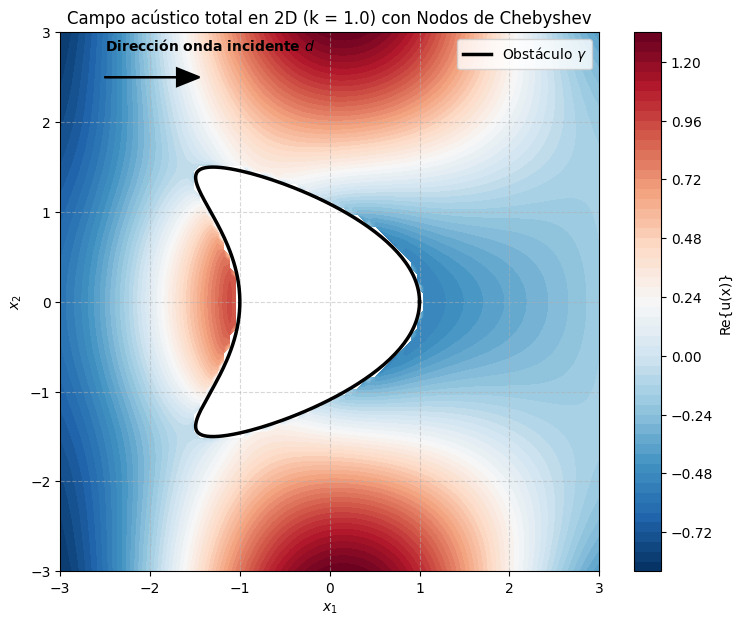

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import hankel1

# ==========================================
# 1. Definición de la Geometría (Curva original de Colton & Kress)
# ==========================================
def curva(t):
    xt = np.cos(t) + 0.65 * np.cos(2 * t) - 0.65
    yt = 1.5 * np.sin(t)
    return np.array([xt, yt])

def curva_derivada(t):
    dxt = -np.sin(t) - 1.3 * np.sin(2 * t)
    dyt = 1.5 * np.cos(t)
    return np.array([dxt, dyt])

def normal_vector(t):
    dt = curva_derivada(t)
    norm = np.linalg.norm(dt, axis=0)
    # Vector normal apuntando correctamente hacia el EXTERIOR
    nx = dt[1] / norm
    ny = -dt[0] / norm
    return np.array([nx, ny])

def phi_incidente(k, d, x):
    return np.exp(1j * k * np.dot(d, x))

def dG_dn(k, x, y, ny):
    diff = y - x
    r = np.linalg.norm(diff, axis=0)
    if r == 0:
        return 0.0
    grad_y_G = -k * hankel1(1, k * r) * (diff / r)
    return np.sum(grad_y_G * ny, axis=0) if ny.ndim > 1 else np.dot(grad_y_G, ny)

def lagrange_basis(t, j, nodes):
    N = len(nodes)
    val = 1.0
    t_j = nodes[j]
    for m in range(N):
        if m == j:
            continue
        t_m = nodes[m]
        val *= (t - t_m) / (t_j - t_m)
    return val


# ==========================================
# 2. Resolución BEM con Nodos de Chebyshev y Kress
# ==========================================
def resolver_bem_con_mapeo(k, d, N):
    # Generación de nodos de Chebyshev para j = 1, ..., N mapeados al intervalo [0, 2*pi]
    # t_cheb_11 in [-1, 1]: cos((2j - 1) * pi / (2N))
    j_indices = np.arange(1, N + 1)
    nodes_raw = np.cos((2 * j_indices - 1) * np.pi / (2 * N))
    # Mapeo lineal desde [-1, 1] hacia [0, 2*pi]
    nodes = np.pi * nodes_raw + np.pi

    M = np.zeros((N, N), dtype=complex)
    b = np.zeros(N, dtype=complex)

    X_nodes = np.array([curva(t) for t in nodes]).T  # Shape (2, N)

    for i in range(N):
        xi = X_nodes[:, i]
        b[i] = -phi_incidente(k, d, xi)

    # Cuadratura con cambio de variable periódico (Transformación de Kress)
    M_quad = 3 * N
    u_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_u = (2 * np.pi) / M_quad

    sigma = 1.0  # Parámetro de suavizado del mapeo
    tau_quad = u_quad - sigma * np.sin(u_quad)
    dtau_du = 1.0 - sigma * np.cos(u_quad)  # Derivada g'(u)

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0) * dtau_du
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    for i in range(N):
        xi = X_nodes[:, i]
        for j in range(N):
            integral_val = 0.0
            for q in range(M_quad):
                t_q = tau_quad[q]
                y_q = X_quad[:, q]
                ny_q = N_quad[:, q]
                dt_norm_q = Norms_dt_quad[q]

                l_j_val = lagrange_basis(t_q, j, nodes)

                # Tratamiento de la diagonal / auto-intersección
                dist_geo = np.linalg.norm(xi - y_q)
                if dist_geo < 1e-12:
                    kernel_val = 0.0
                else:
                    kernel_val = dG_dn(k, xi, y_q, ny_q)

                integral_val += kernel_val * l_j_val * dt_norm_q * w_u

            delta_ij = 1.0 if i == j else 0.0
            M[i, j] = 0.5 * delta_ij + integral_val

    a = np.linalg.solve(M, b)
    return nodes, a, X_nodes


# ==========================================
# 3. Evaluación 2D Vectorizada y Optimizada
# ==========================================
def evaluar_campo_2d(k, d, X_nodes, a_coefs, grid_x, grid_y):
    Ny, Nx = grid_x.shape
    X_grid = np.stack([grid_x.ravel(), grid_y.ravel()], axis=-1)  # Shape: (P, 2)
    P = X_grid.shape[0]

    u_inc = np.exp(1j * k * (X_grid @ d)).reshape(Ny, Nx)

    M_quad = 120
    tau_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_quad = (2 * np.pi) / M_quad

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0)
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    N_nodes_len = len(a_coefs)
    j_indices = np.arange(1, N_nodes_len + 1)
    nodes = np.pi * np.cos((2 * j_indices - 1) * np.pi / (2 * N_nodes_len)) + np.pi

    L_matrix = np.zeros((N_nodes_len, M_quad))
    for j in range(N_nodes_len):
        for q, t_q in enumerate(tau_quad):
            L_matrix[j, q] = lagrange_basis(t_q, j, nodes)

    phi_quad = a_coefs @ L_matrix  # Shape: (M_quad,)

    u_scat_flat = np.zeros(P, dtype=complex)
    eps_reg = 0.02  # Suavizado físico para evitar singularidades estéticas en la malla 2D

    for q in range(M_quad):
        y_q = X_quad[:, q]
        ny_q = N_quad[:, q]
        dt_norm = Norms_dt_quad[q]
        phi_q = phi_quad[q]

        diff = y_q - X_grid
        r_exact = np.linalg.norm(diff, axis=1)
        r_reg = np.sqrt(r_exact**2 + eps_reg**2)

        grad_y_G = -k * hankel1(1, k * r_reg[:, None]) * (diff / r_reg[:, None])
        dG_dn_vals = np.sum(grad_y_G * ny_q, axis=1)

        u_scat_flat += dG_dn_vals * phi_q * dt_norm * w_quad

    u_scat = u_scat_flat.reshape(Ny, Nx)
    return u_inc + u_scat


# ==========================================
# 4. Ejecución Principal y Visualización
# ==========================================
if __name__ == "__main__":
    k_par = 1.0
    d_par = np.array([1.0, 0.0])  # Incidencia de izquierda a derecha
    N_nodes = 50                  # Número de nodos

    print("Resolviendo BEM con nodos de Chebyshev y cambio de variable...")
    nodes, a_coefs, X_nodes = resolver_bem_con_mapeo(k_par, d_par, N_nodes)

    print("Calculando campo en la malla 2D...")
    resolution = 90
    x_vals = np.linspace(-3.0, 3.0, resolution)
    y_vals = np.linspace(-3.0, 3.0, resolution)
    GX, GY = np.meshgrid(x_vals, y_vals)

    U_field = evaluar_campo_2d(k_par, d_par, X_nodes, a_coefs, GX, GY)

    # Enmascarar el interior del obstáculo para evitar visualización incorrecta
    from matplotlib.path import Path
    t_plot_path = np.linspace(0, 2 * np.pi, 300)
    puntos_plot_path = np.array([curva(t) for t in t_plot_path])
    path_obstaculo = Path(puntos_plot_path)
    grid_points = np.stack([GX.ravel(), GY.ravel()], axis=-1)
    dentro = path_obstaculo.contains_points(grid_points).reshape(GX.shape)

    U_field_masked = np.array(U_field, dtype=complex)
    U_field_masked[dentro] = np.nan

    # Gráfico 2D
    plt.figure(figsize=(9, 7))
    contour = plt.contourf(GX, GY, np.real(U_field_masked), levels=60, cmap='RdBu_r')
    plt.colorbar(contour, label='Re{u(x)}')

    # Dibujar obstáculo
    t_plot = np.linspace(0, 2 * np.pi, 300)
    puntos_plot = np.array([curva(t) for t in t_plot])
    xt_obs, yt_obs = puntos_plot[:, 0], puntos_plot[:, 1]

    plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Obstáculo $\gamma$')
    plt.fill(xt_obs, yt_obs, color='white', alpha=0.35)

    # Flecha de dirección de la onda incidente
    plt.arrow(-2.5, 2.5, 0.8, 0.0, head_width=0.2, head_length=0.25,
              fc='black', ec='black', linewidth=1.5, zorder=5)
    plt.text(-2.5, 2.8, 'Dirección onda incidente $d$', fontsize=10, fontweight='bold', color='black')

    plt.title(f'Campo acústico total en 2D (k = {k_par}) con Nodos de Chebyshev')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

<>:203: SyntaxWarning: invalid escape sequence '\g'
<>:203: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1102/3214407699.py:203: SyntaxWarning: invalid escape sequence '\g'
  plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Obstáculo $\gamma$')


Resolviendo BEM con nodos de Chebyshev y cambio de variable...
Calculando campo en la malla 2D...


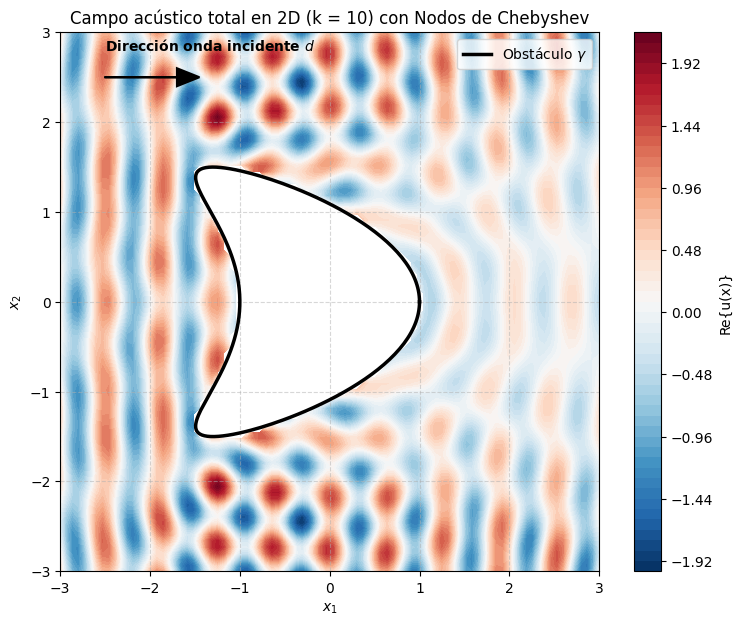

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import hankel1

# ==========================================
# 1. Definición de la Geometría (Curva original de Colton & Kress)
# ==========================================
def curva(t):
    xt = np.cos(t) + 0.65 * np.cos(2 * t) - 0.65
    yt = 1.5 * np.sin(t)
    return np.array([xt, yt])

def curva_derivada(t):
    dxt = -np.sin(t) - 1.3 * np.sin(2 * t)
    dyt = 1.5 * np.cos(t)
    return np.array([dxt, dyt])

def normal_vector(t):
    dt = curva_derivada(t)
    norm = np.linalg.norm(dt, axis=0)
    # Vector normal apuntando correctamente hacia el EXTERIOR
    nx = dt[1] / norm
    ny = -dt[0] / norm
    return np.array([nx, ny])

def phi_incidente(k, d, x):
    return np.exp(1j * k * np.dot(d, x))

def dG_dn(k, x, y, ny):
    diff = y - x
    r = np.linalg.norm(diff, axis=0)
    if r == 0:
        return 0.0
    grad_y_G = -k * hankel1(1, k * r) * (diff / r)
    return np.sum(grad_y_G * ny, axis=0) if ny.ndim > 1 else np.dot(grad_y_G, ny)

def lagrange_basis(t, j, nodes):
    N = len(nodes)
    val = 1.0
    t_j = nodes[j]
    for m in range(N):
        if m == j:
            continue
        t_m = nodes[m]
        val *= (t - t_m) / (t_j - t_m)
    return val


# ==========================================
# 2. Resolución BEM con Nodos de Chebyshev y Kress
# ==========================================
def resolver_bem_con_mapeo(k, d, N):
    # Generación de nodos de Chebyshev para j = 1, ..., N mapeados al intervalo [0, 2*pi]
    # t_cheb_11 in [-1, 1]: cos((2j - 1) * pi / (2N))
    j_indices = np.arange(1, N + 1)
    nodes_raw = np.cos((2 * j_indices - 1) * np.pi / (2 * N))
    # Mapeo lineal desde [-1, 1] hacia [0, 2*pi]
    nodes = np.pi * nodes_raw + np.pi

    M = np.zeros((N, N), dtype=complex)
    b = np.zeros(N, dtype=complex)

    X_nodes = np.array([curva(t) for t in nodes]).T  # Shape (2, N)

    for i in range(N):
        xi = X_nodes[:, i]
        b[i] = -phi_incidente(k, d, xi)

    # Cuadratura con cambio de variable periódico (Transformación de Kress)
    M_quad = 3 * N
    u_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_u = (2 * np.pi) / M_quad

    sigma = 1.0  # Parámetro de suavizado del mapeo
    tau_quad = u_quad - sigma * np.sin(u_quad)
    dtau_du = 1.0 - sigma * np.cos(u_quad)  # Derivada g'(u)

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0) * dtau_du
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    for i in range(N):
        xi = X_nodes[:, i]
        for j in range(N):
            integral_val = 0.0
            for q in range(M_quad):
                t_q = tau_quad[q]
                y_q = X_quad[:, q]
                ny_q = N_quad[:, q]
                dt_norm_q = Norms_dt_quad[q]

                l_j_val = lagrange_basis(t_q, j, nodes)

                # Tratamiento de la diagonal / auto-intersección
                dist_geo = np.linalg.norm(xi - y_q)
                if dist_geo < 1e-12:
                    kernel_val = 0.0
                else:
                    kernel_val = dG_dn(k, xi, y_q, ny_q)

                integral_val += kernel_val * l_j_val * dt_norm_q * w_u

            delta_ij = 1.0 if i == j else 0.0
            M[i, j] = 0.5 * delta_ij + integral_val

    a = np.linalg.solve(M, b)
    return nodes, a, X_nodes


# ==========================================
# 3. Evaluación 2D Vectorizada y Optimizada
# ==========================================
def evaluar_campo_2d(k, d, X_nodes, a_coefs, grid_x, grid_y):
    Ny, Nx = grid_x.shape
    X_grid = np.stack([grid_x.ravel(), grid_y.ravel()], axis=-1)  # Shape: (P, 2)
    P = X_grid.shape[0]

    u_inc = np.exp(1j * k * (X_grid @ d)).reshape(Ny, Nx)

    M_quad = 120
    tau_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_quad = (2 * np.pi) / M_quad

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0)
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    N_nodes_len = len(a_coefs)
    j_indices = np.arange(1, N_nodes_len + 1)
    nodes = np.pi * np.cos((2 * j_indices - 1) * np.pi / (2 * N_nodes_len)) + np.pi

    L_matrix = np.zeros((N_nodes_len, M_quad))
    for j in range(N_nodes_len):
        for q, t_q in enumerate(tau_quad):
            L_matrix[j, q] = lagrange_basis(t_q, j, nodes)

    phi_quad = a_coefs @ L_matrix  # Shape: (M_quad,)

    u_scat_flat = np.zeros(P, dtype=complex)
    eps_reg = 0.02  # Suavizado físico para evitar singularidades estéticas en la malla 2D

    for q in range(M_quad):
        y_q = X_quad[:, q]
        ny_q = N_quad[:, q]
        dt_norm = Norms_dt_quad[q]
        phi_q = phi_quad[q]

        diff = y_q - X_grid
        r_exact = np.linalg.norm(diff, axis=1)
        r_reg = np.sqrt(r_exact**2 + eps_reg**2)

        grad_y_G = -k * hankel1(1, k * r_reg[:, None]) * (diff / r_reg[:, None])
        dG_dn_vals = np.sum(grad_y_G * ny_q, axis=1)

        u_scat_flat += dG_dn_vals * phi_q * dt_norm * w_quad

    u_scat = u_scat_flat.reshape(Ny, Nx)
    return u_inc + u_scat


# ==========================================
# 4. Ejecución Principal y Visualización
# ==========================================
if __name__ == "__main__":
    k_par = 10
    d_par = np.array([1.0, 0.0])  # Incidencia de izquierda a derecha
    N_nodes = 100                  # Número de nodos

    print("Resolviendo BEM con nodos de Chebyshev y cambio de variable...")
    nodes, a_coefs, X_nodes = resolver_bem_con_mapeo(k_par, d_par, N_nodes)

    print("Calculando campo en la malla 2D...")
    resolution = 90
    x_vals = np.linspace(-3.0, 3.0, resolution)
    y_vals = np.linspace(-3.0, 3.0, resolution)
    GX, GY = np.meshgrid(x_vals, y_vals)

    U_field = evaluar_campo_2d(k_par, d_par, X_nodes, a_coefs, GX, GY)

    # Enmascarar el interior del obstáculo para evitar visualización incorrecta
    from matplotlib.path import Path
    t_plot_path = np.linspace(0, 2 * np.pi, 300)
    puntos_plot_path = np.array([curva(t) for t in t_plot_path])
    path_obstaculo = Path(puntos_plot_path)
    grid_points = np.stack([GX.ravel(), GY.ravel()], axis=-1)
    dentro = path_obstaculo.contains_points(grid_points).reshape(GX.shape)

    U_field_masked = np.array(U_field, dtype=complex)
    U_field_masked[dentro] = np.nan

    # Gráfico 2D
    plt.figure(figsize=(9, 7))
    contour = plt.contourf(GX, GY, np.real(U_field_masked), levels=60, cmap='RdBu_r')
    plt.colorbar(contour, label='Re{u(x)}')

    # Dibujar obstáculo
    t_plot = np.linspace(0, 2 * np.pi, 300)
    puntos_plot = np.array([curva(t) for t in t_plot])
    xt_obs, yt_obs = puntos_plot[:, 0], puntos_plot[:, 1]

    plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Obstáculo $\gamma$')
    plt.fill(xt_obs, yt_obs, color='white', alpha=0.35)

    # Flecha de dirección de la onda incidente
    plt.arrow(-2.5, 2.5, 0.8, 0.0, head_width=0.2, head_length=0.25,
              fc='black', ec='black', linewidth=1.5, zorder=5)
    plt.text(-2.5, 2.8, 'Dirección onda incidente $d$', fontsize=10, fontweight='bold', color='black')

    plt.title(f'Campo acústico total en 2D (k = {k_par}) con Nodos de Chebyshev')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

## CONVERGENCIA

Calculando solución de referencia de alta precisión...

Analizando convergencia en el punto [2. 1.]:
--------------------------------------------------
N = 10 | u_total = -0.187340-0.089053j | Error absoluto = 1.53e-02
N = 15 | u_total = -0.181212-0.101476j | Error absoluto = 1.49e-03
N = 20 | u_total = -0.180341-0.102994j | Error absoluto = 5.91e-04
N = 25 | u_total = -0.180917-0.103011j | Error absoluto = 7.05e-05
N = 30 | u_total = -0.180928-0.102941j | Error absoluto = 1.88e-06
--------------------------------------------------


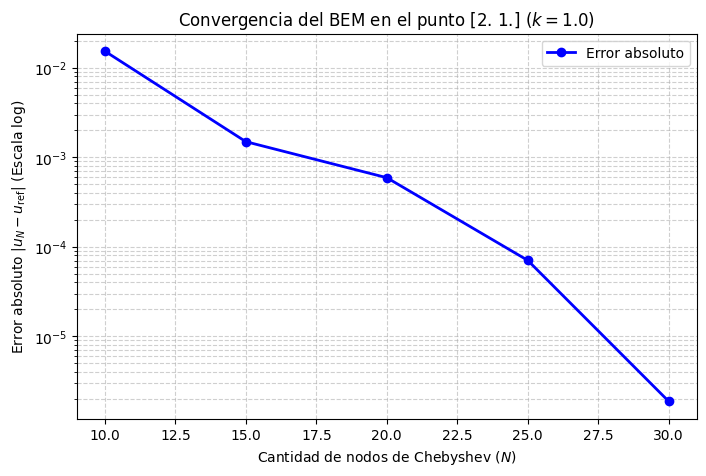

In [ ]:
# ==========================================
# 5. Celda de Análisis de Convergencia en un Punto
# ==========================================
if __name__ == "__main__":
    k_par = 1.0
    d_par = np.array([1.0, 0.0])  # Incidencia de izquierda a derecha

    # Definimos un punto de prueba fijo en el espacio exterior (fuera de la cometa)
    punto_prueba = np.array([2.0, 1.0])

    # Lista de cantidades de nodos a evaluar
    lista_N = [10, 15, 20, 25, 30]

    print(f"Calculando solución de referencia de alta precisión...")
    N_ref = 50
    nodes_ref, a_ref, X_nodes_ref = resolver_bem_con_mapeo(k_par, d_par, N_ref)

    # Función auxiliar optimizada para evaluar el campo acústico en un ÚNICO punto x
    def evaluar_campo_en_punto(k, d, a_coefs, x_punt):
        M_quad = 120
        tau_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
        w_quad = (2 * np.pi) / M_quad

        X_quad = np.array([curva(t) for t in tau_quad]).T
        D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
        Norms_dt_quad = np.linalg.norm(D_quad, axis=0)
        N_quad = np.array([normal_vector(t) for t in tau_quad]).T

        N_nodes_len = len(a_coefs)
        j_indices = np.arange(1, N_nodes_len + 1)
        nodes = np.pi * np.cos((2 * j_indices - 1) * np.pi / (2 * N_nodes_len)) + np.pi

        L_matrix = np.zeros((N_nodes_len, M_quad))
        for j in range(N_nodes_len):
            for q, t_q in enumerate(tau_quad):
                L_matrix[j, q] = lagrange_basis(t_q, j, nodes)

        phi_quad = a_coefs @ L_matrix  # Densidad sobre la cuadratura

        u_scat = 0.0
        for q in range(M_quad):
            y_q = X_quad[:, q]
            ny_q = N_quad[:, q]
            dt_norm = Norms_dt_quad[q]
            phi_q = phi_quad[q]

            diff = y_q - x_punt
            r = np.linalg.norm(diff)

            grad_y_G = -k * hankel1(1, k * r) * (diff / r)
            dG_dn_val = np.dot(grad_y_G, ny_q)

            u_scat += dG_dn_val * phi_q * dt_norm * w_quad

        u_inc = np.exp(1j * k * np.dot(d, x_punt))
        return u_inc + u_scat

    # Obtener el valor de referencia en el punto de prueba
    u_ref = evaluar_campo_en_punto(k_par, d_par, a_ref, punto_prueba)

    # Evaluar el error para cada N
    errores = []
    print(f"\nAnalizando convergencia en el punto {punto_prueba}:")
    print("-" * 50)
    for N in lista_N:
        nodes, a_coefs, X_nodes = resolver_bem_con_mapeo(k_par, d_par, N)
        u_n = evaluar_campo_en_punto(k_par, d_par, a_coefs, punto_prueba)
        error = np.abs(u_n - u_ref)
        errores.append(error)
        print(f"N = {N:2d} | u_total = {u_n:.6f} | Error absoluto = {error:.2e}")

    print("-" * 50)

    # Gráfica de convergencia (Escala Logarítmica)
    plt.figure(figsize=(8, 5))
    plt.semilogy(lista_N, errores, 'bo-', linewidth=2, markersize=6, label='Error absoluto')
    plt.title(f'Convergencia del BEM en el punto {punto_prueba} ($k = {k_par}$)')
    plt.xlabel('Cantidad de nodos de Chebyshev ($N$)')
    plt.ylabel('Error absoluto $|u_N - u_{\\text{ref}}|$ (Escala log)')
    plt.grid(True, which="both", linestyle='--', alpha=0.6)
    plt.legend(loc='upper right')
    plt.show()

## Caso puntiagudo

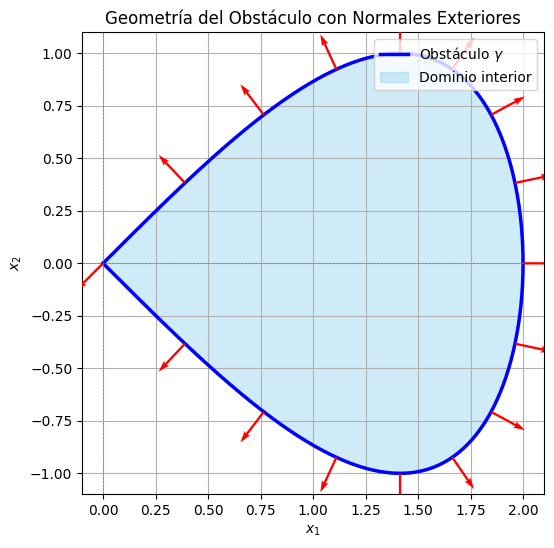

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def curva(t):
    xt = 2 * np.sin(t / 2)
    yt = -np.sin(t)
    return np.array([xt, yt])

def curva_derivada(t):
    dxt = np.cos(t / 2)
    dyt = -np.cos(t)
    return np.array([dxt, dyt])

def normal_vector(t):
    dt = curva_derivada(t)
    norm = np.linalg.norm(dt, axis=0)
    # Vector normal apuntando correctamente hacia el EXTERIOR
    nx = dt[1] / norm
    ny = -dt[0] / norm
    return np.array([nx, ny])

def plot_obstaculo():
    # 1. Discretizar el parámetro t en [0, 2*pi]
    t_vals = np.linspace(0, 2 * np.pi, 400)

    # 2. Evaluar la curva punto a punto
    puntos = np.array([curva(ti) for ti in t_vals])
    xt, yt = puntos[:, 0], puntos[:, 1]

    plt.figure(figsize=(6, 6))

    # 3. Graficar el contorno y rellenar el interior
    plt.plot(xt, yt, 'b-', linewidth=2.5, label='Obstáculo $\\gamma$')
    plt.fill(xt, yt, color='skyblue', alpha=0.4, label='Dominio interior')

    # 4. Dibujar vectores normales exteriores para control visual
    t_quiver = np.linspace(0, 2 * np.pi, 16, endpoint=False)
    for ti in t_quiver:
        pos = curva(ti)
        n = normal_vector(ti)
        plt.quiver(pos[0], pos[1], n[0], n[1], color='red', scale=12, width=0.005, zorder=3)

    # Estética del gráfico
    plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
    plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.title('Geometría del Obstáculo con Normales Exteriores')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.show()

# Ejecutar la función
plot_obstaculo()

<>:196: SyntaxWarning: invalid escape sequence '\g'
<>:196: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1102/1925828729.py:196: SyntaxWarning: invalid escape sequence '\g'
  plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Nuevo Obstáculo $\gamma$')


Resolviendo BEM para la nueva geometría...
Calculando campo en la malla 2D...


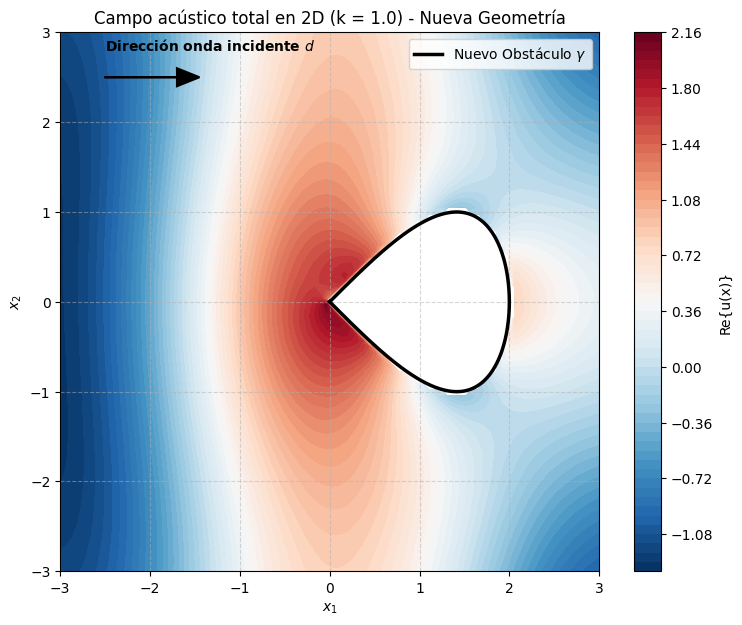

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import hankel1
from matplotlib.path import Path

# ==========================================
# 1. Definición de la Nueva Geometría
# ==========================================
def curva(t):
    xt = 2 * np.sin(t / 2)
    yt = -np.sin(t)
    return np.array([xt, yt])

def curva_derivada(t):
    dxt = np.cos(t / 2)
    dyt = -np.cos(t)
    return np.array([dxt, dyt])

def normal_vector(t):
    dt = curva_derivada(t)
    norm = np.linalg.norm(dt, axis=0)
    # Vector normal apuntando correctamente hacia el EXTERIOR
    nx = dt[1] / norm
    ny = -dt[0] / norm
    return np.array([nx, ny])

def phi_incidente(k, d, x):
    return np.exp(1j * k * np.dot(d, x))

def dG_dn(k, x, y, ny):
    diff = y - x
    r = np.linalg.norm(diff, axis=0)
    if r == 0:
        return 0.0
    grad_y_G = -k * hankel1(1, k * r) * (diff / r)
    return np.sum(grad_y_G * ny, axis=0) if ny.ndim > 1 else np.dot(grad_y_G, ny)

def lagrange_basis(t, j, nodes):
    N = len(nodes)
    val = 1.0
    t_j = nodes[j]
    for m in range(N):
        if m == j:
            continue
        t_m = nodes[m]
        val *= (t - t_m) / (t_j - t_m)
    return val


# ==========================================
# 2. Resolución BEM con Nodos de Chebyshev y Kress
# ==========================================
def resolver_bem_con_mapeo(k, d, N):
    j_indices = np.arange(1, N + 1)
    nodes_raw = np.cos((2 * j_indices - 1) * np.pi / (2 * N))
    nodes = np.pi * nodes_raw + np.pi  # Mapeo a [0, 2*pi]

    M = np.zeros((N, N), dtype=complex)
    b = np.zeros(N, dtype=complex)

    X_nodes = np.array([curva(t) for t in nodes]).T  # Shape (2, N)

    for i in range(N):
        xi = X_nodes[:, i]
        b[i] = -phi_incidente(k, d, xi)

    # Cuadratura con cambio de variable periódico (Transformación de Kress)
    M_quad = 3 * N
    u_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_u = (2 * np.pi) / M_quad

    sigma = 1.0
    tau_quad = u_quad - sigma * np.sin(u_quad)
    dtau_du = 1.0 - sigma * np.cos(u_quad)

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0) * dtau_du
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    for i in range(N):
        xi = X_nodes[:, i]
        for j in range(N):
            integral_val = 0.0
            for q in range(M_quad):
                t_q = tau_quad[q]
                y_q = X_quad[:, q]
                ny_q = N_quad[:, q]
                dt_norm_q = Norms_dt_quad[q]

                l_j_val = lagrange_basis(t_q, j, nodes)

                dist_geo = np.linalg.norm(xi - y_q)
                if dist_geo < 1e-12:
                    kernel_val = 0.0
                else:
                    kernel_val = dG_dn(k, xi, y_q, ny_q)

                integral_val += kernel_val * l_j_val * dt_norm_q * w_u

            delta_ij = 1.0 if i == j else 0.0
            M[i, j] = 0.5 * delta_ij + integral_val

    a = np.linalg.solve(M, b)
    return nodes, a, X_nodes


# ==========================================
# 3. Evaluación 2D Vectorizada y Optimizada
# ==========================================
def evaluar_campo_2d(k, d, X_nodes, a_coefs, grid_x, grid_y):
    Ny, Nx = grid_x.shape
    X_grid = np.stack([grid_x.ravel(), grid_y.ravel()], axis=-1)
    P = X_grid.shape[0]

    u_inc = np.exp(1j * k * (X_grid @ d)).reshape(Ny, Nx)

    M_quad = 120
    tau_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
    w_quad = (2 * np.pi) / M_quad

    X_quad = np.array([curva(t) for t in tau_quad]).T
    D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
    Norms_dt_quad = np.linalg.norm(D_quad, axis=0)
    N_quad = np.array([normal_vector(t) for t in tau_quad]).T

    N_nodes_len = len(a_coefs)
    j_indices = np.arange(1, N_nodes_len + 1)
    nodes = np.pi * np.cos((2 * j_indices - 1) * np.pi / (2 * N_nodes_len)) + np.pi

    L_matrix = np.zeros((N_nodes_len, M_quad))
    for j in range(N_nodes_len):
        for q, t_q in enumerate(tau_quad):
            L_matrix[j, q] = lagrange_basis(t_q, j, nodes)

    phi_quad = a_coefs @ L_matrix

    u_scat_flat = np.zeros(P, dtype=complex)
    eps_reg = 0.02

    for q in range(M_quad):
        y_q = X_quad[:, q]
        ny_q = N_quad[:, q]
        dt_norm = Norms_dt_quad[q]
        phi_q = phi_quad[q]

        diff = y_q - X_grid
        r_exact = np.linalg.norm(diff, axis=1)
        r_reg = np.sqrt(r_exact**2 + eps_reg**2)

        grad_y_G = -k * hankel1(1, k * r_reg[:, None]) * (diff / r_reg[:, None])
        dG_dn_vals = np.sum(grad_y_G * ny_q, axis=1)

        u_scat_flat += dG_dn_vals * phi_q * dt_norm * w_quad

    u_scat = u_scat_flat.reshape(Ny, Nx)
    return u_inc + u_scat


# ==========================================
# 4. Ejecución Principal y Visualización
# ==========================================
if __name__ == "__main__":
    k_par = 1.0
    d_par = np.array([1.0, 0.0])  # Incidencia de izquierda a derecha
    N_nodes = 50                  # Número de nodos

    print("Resolviendo BEM para la nueva geometría...")
    nodes, a_coefs, X_nodes = resolver_bem_con_mapeo(k_par, d_par, N_nodes)

    print("Calculando campo en la malla 2D...")
    resolution = 90
    x_vals = np.linspace(-3.0, 3.0, resolution)
    y_vals = np.linspace(-3.0, 3.0, resolution)
    GX, GY = np.meshgrid(x_vals, y_vals)

    U_field = evaluar_campo_2d(k_par, d_par, X_nodes, a_coefs, GX, GY)

    # Enmascarar el interior del nuevo obstáculo
    t_plot_path = np.linspace(0, 2 * np.pi, 300)
    puntos_plot_path = np.array([curva(t) for t in t_plot_path])
    path_obstaculo = Path(puntos_plot_path)
    grid_points = np.stack([GX.ravel(), GY.ravel()], axis=-1)
    dentro = path_obstaculo.contains_points(grid_points).reshape(GX.shape)

    U_field_masked = np.array(U_field, dtype=complex)
    U_field_masked[dentro] = np.nan

    # Gráfico 2D
    plt.figure(figsize=(9, 7))
    contour = plt.contourf(GX, GY, np.real(U_field_masked), levels=60, cmap='RdBu_r')
    plt.colorbar(contour, label='Re{u(x)}')

    # Dibujar obstáculo
    xt_obs, yt_obs = puntos_plot_path[:, 0], puntos_plot_path[:, 1]
    plt.plot(xt_obs, yt_obs, 'k-', linewidth=2.5, label='Nuevo Obstáculo $\gamma$')
    plt.fill(xt_obs, yt_obs, color='white', alpha=0.35)

    # Flecha de dirección de la onda incidente
    plt.arrow(-2.5, 2.5, 0.8, 0.0, head_width=0.2, head_length=0.25,
              fc='black', ec='black', linewidth=1.5, zorder=5)
    plt.text(-2.5, 2.8, 'Dirección onda incidente $d$', fontsize=10, fontweight='bold', color='black')

    plt.title(f'Campo acústico total en 2D (k = {k_par}) - Nueva Geometría')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

Calculando solución de referencia de alta precisión (N = 80)...
Valor de referencia (N=50): 0.067124+0.176296j

N     | u_total (Real + Imag)        | Error Absoluto
10    | (0.070726+0.169167j)         | 7.99e-03
15    | (0.066385+0.177066j)         | 1.07e-03
20    | (0.066962+0.176872j)         | 5.98e-04
25    | (0.067182+0.176722j)         | 4.29e-04
30    | (0.067219+0.176548j)         | 2.69e-04
35    | (0.067212+0.176432j)         | 1.62e-04
40    | (0.067183+0.176359j)         | 8.64e-05
45    | (0.067151+0.176316j)         | 3.38e-05
50    | (0.067124+0.176296j)         | 0.00e+00


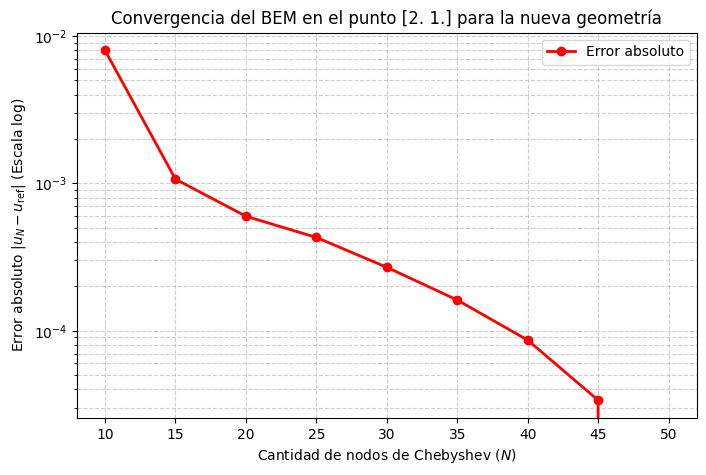

In [ ]:
# ==========================================
# 5. Análisis de Convergencia para la Nueva Geometría (hasta N = 50)
# ==========================================
if __name__ == "__main__":
    k_par = 1.0
    d_par = np.array([1.0, 0.0])  # Incidencia de izquierda a derecha

    # Definimos un punto de prueba fijo en el espacio exterior
    punto_prueba = np.array([2.0, 1.0])

    # Lista de nodos a evaluar hasta N = 50
    lista_N = [10, 15, 20, 25, 30, 35, 40, 45, 50]

    print("Calculando solución de referencia de alta precisión (N = 80)...")
    N_ref = 50
    nodes_ref, a_ref, X_nodes_ref = resolver_bem_con_mapeo(k_par, d_par, N_ref)

    # Función auxiliar para evaluar el campo en un punto específico
    def evaluar_campo_en_punto(k, d, a_coefs, x_punt):
        M_quad = 120
        tau_quad = np.linspace(0, 2 * np.pi, M_quad, endpoint=False)
        w_quad = (2 * np.pi) / M_quad

        X_quad = np.array([curva(t) for t in tau_quad]).T
        D_quad = np.array([curva_derivada(t) for t in tau_quad]).T
        Norms_dt_quad = np.linalg.norm(D_quad, axis=0)
        N_quad = np.array([normal_vector(t) for t in tau_quad]).T

        N_nodes_len = len(a_coefs)
        j_indices = np.arange(1, N_nodes_len + 1)
        nodes = np.pi * np.cos((2 * j_indices - 1) * np.pi / (2 * N_nodes_len)) + np.pi

        L_matrix = np.zeros((N_nodes_len, M_quad))
        for j in range(N_nodes_len):
            for q, t_q in enumerate(tau_quad):
                L_matrix[j, q] = lagrange_basis(t_q, j, nodes)

        phi_quad = a_coefs @ L_matrix

        u_scat = 0.0
        for q in range(M_quad):
            y_q = X_quad[:, q]
            ny_q = N_quad[:, q]
            dt_norm = Norms_dt_quad[q]
            phi_q = phi_quad[q]

            diff = y_q - x_punt
            r = np.linalg.norm(diff)

            grad_y_G = -k * hankel1(1, k * r) * (diff / r)
            dG_dn_val = np.dot(grad_y_G, ny_q)

            u_scat += dG_dn_val * phi_q * dt_norm * w_quad

        u_inc = np.exp(1j * k * np.dot(d, x_punt))
        return u_inc + u_scat

    # Obtener el valor de referencia en el punto de prueba
    u_ref = evaluar_campo_en_punto(k_par, d_par, a_ref, punto_prueba)
    print(f"Valor de referencia (N={N_ref}): {u_ref:.6f}")

    # Evaluar el campo y el error para cada N hasta 50
    valores_u = []
    errores = []
    print("\n" + "="*65)
    print(f"{'N':<5} | {'u_total (Real + Imag)':<28} | {'Error Absoluto'}")
    print("="*65)

    for N in lista_N:
        nodes, a_coefs, X_nodes = resolver_bem_con_mapeo(k_par, d_par, N)
        u_n = evaluar_campo_en_punto(k_par, d_par, a_coefs, punto_prueba)
        error = np.abs(u_n - u_ref)
        valores_u.append(u_n)
        errores.append(error)
        print(f"{N:<5} | {str(np.round(u_n, 6)):<28} | {error:.2e}")

    print("="*65)

    # Gráfica de convergencia en escala logarítmica
    plt.figure(figsize=(8, 5))
    plt.semilogy(lista_N, errores, 'ro-', linewidth=2, markersize=6, label='Error absoluto')
    plt.title(f'Convergencia del BEM en el punto {punto_prueba} para la nueva geometría')
    plt.xlabel('Cantidad de nodos de Chebyshev ($N$)')
    plt.ylabel('Error absoluto $|u_N - u_{\\text{ref}}|$ (Escala log)')
    plt.grid(True, which="both", linestyle='--', alpha=0.6)
    plt.legend(loc='upper right')
    plt.show()